# Distorted Visual Sequence Pattern Recognition using Deep Learning

**Name:** Eshita Bhatia
**Enrollment No.:** 24112044

## Problem Overview

The task is to read a sequence of alphanumeric characters from a grayscale image that has been deliberately made difficult to read. Each image contains a six character sequence affected by a large black blob that partially covers the text, dense speckle noise across the background, and irregular character spacing caused by the blob's position shifting across images.

## Approach and Methodology

The core challenge is that characters are not pre-segmented in the image. There are no bounding boxes and no alignment information telling the model where each character starts or ends. A standard fixed-output classifier would need to know this in advance, which makes it unsuitable here.

The chosen solution is a CRNN (Convolutional Recurrent Neural Network) trained with CTC (Connectionist Temporal Classification) loss. The pipeline works in three stages. First, a ResNet-style convolutional backbone processes the image and produces a left-to-right sequence of feature vectors, one per spatial column across the image width. Second, a bidirectional LSTM reads this sequence in both directions simultaneously, which is important for recovering partially occluded characters since the model can use context from both sides of a hidden glyph. Third, CTC maps the roughly 49 CNN time steps down to the 6-character label without requiring any per-character location annotation during training. CTC marginalises over all possible alignments between time steps and label characters, so the model learns character identities and their ordering purely from image-label pairs.

The evaluation metric is Character Error Rate (CER), defined as the total Levenshtein edit distance across all predictions divided by the total number of characters in the ground truth labels. Lower is better. The model checkpoint is saved whenever validation CER improves rather than when loss improves, since CER is the actual leaderboard metric.

## 1. Mount Google Drive and Extract Dataset

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os
zip_path   = '/content/drive/MyDrive/dataset.zip'
extract_to = '/content/'

if not os.path.exists('/content/cig_ps/train_images'):
    print('Extracting dataset...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_to)
    print('Done.')
else:
    print('Already extracted.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already extracted.


## 2. Install Dependencies

In [5]:
!pip install editdistance --quiet


## 3. Imports and Device Setup

In [6]:
import os, re, time, random
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import editdistance

print('PyTorch:', torch.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


## 4. Reproducibility

In [7]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
print('Seed set to', SEED)


Seed set to 42


## 5. Paths and Hyperparameters

All paths and training settings are defined here in one place so the notebook is fully reproducible. Changing a hyperparameter or path only requires editing this cell.

The images in this dataset are 200 by 100 pixels. Resizing to height 32 (the standard input height for CRNN models) while keeping the width at 200 preserves the original 2:1 aspect ratio. This avoids horizontal compression of the characters and gives the CNN approximately 49 output time steps, which is well above the minimum CTC requires for labels of length 6.

In [8]:
# Paths
TRAIN_DIR  = '/content/cig_ps/train_images'
TEST_DIR   = '/content/cig_ps/test_images'
LABELS_CSV = '/content/cig_ps/train-labels.csv'
CKPT_PATH  = '/content/crnn_best.pt'

# Image
IMG_H = 32
IMG_W = 200

# Training
BATCH_SIZE   = 64
EPOCHS       = 80
LR           = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRAC     = 0.10
GRAD_CLIP    = 5.0
NUM_WORKERS  = 2

# Model
RNN_HIDDEN = 256
DROPOUT    = 0.3

# Submission
name      = 'Eshita_Bhatia'
ENROLL_NO = '24112044'

for p in [TRAIN_DIR, TEST_DIR, LABELS_CSV]:
    print('OK     ' if os.path.exists(p) else 'MISSING', p)


OK      /content/cig_ps/train_images
OK      /content/cig_ps/test_images
OK      /content/cig_ps/train-labels.csv


## 6. Load Labels and Build the Character Vocabulary

The CSV has three columns: a row index, the image filename, and the text label. Only the filename and label columns are loaded. Labels are uppercased to ensure consistency since the images contain only uppercase alphanumeric characters.

The character vocabulary is built directly from the training labels rather than being hard-coded. Index 0 is reserved for the CTC blank token, which CTC uses internally to mark unused time steps and to separate consecutive identical characters. All actual characters are assigned indices starting from 1.

In [9]:
labels_df = pd.read_csv(LABELS_CSV)
labels_df = labels_df[['image', 'text']].copy()
labels_df.columns = ['image', 'label']
labels_df['label'] = labels_df['label'].astype(str).str.upper().str.strip()
labels_df = labels_df.dropna().reset_index(drop=True)
print('Raw samples:', len(labels_df))

labels_df['label_length'] = labels_df['label'].str.len()
bad = labels_df[labels_df['label_length'] != 6]
print(f'Dropping {len(bad)} rows with label length != 6')
labels_df = labels_df[labels_df['label_length'] == 6].reset_index(drop=True)
print('Clean samples:', len(labels_df))
print(labels_df.head(6).to_string(index=False))


Raw samples: 20000
Dropping 2 rows with label length != 6
Clean samples: 19998
      image  label  label_length
train-0.png BU522X             6
train-1.png XQ8NE2             6
train-2.png DTZD3E             6
train-3.png SM424H             6
train-4.png 6YVTQR             6
train-5.png YV2C3D             6


In [10]:
charset     = sorted(set(''.join(labels_df['label'].tolist())))
itos        = ['<blank>'] + charset
stoi        = {c: i for i, c in enumerate(itos)}
NUM_CLASSES = len(itos)
print('Charset:', ''.join(charset))
print('Num classes (incl. blank):', NUM_CLASSES)

def encode_label(text):
    return [stoi[c] for c in text if c in stoi]

def decode_greedy(logits):
    indices = logits.argmax(dim=2).cpu().numpy()
    results = []
    for row in indices:
        chars, prev = [], -1
        for idx in row:
            if idx != prev and idx != 0:
                chars.append(itos[idx])
            prev = idx
        results.append(''.join(chars))
    return results


Charset: 23456789ABCDEFGHJKMNPQRSTUVWXYZ
Num classes (incl. blank): 32


## 7. Exploratory Data Analysis

Before training it is useful to understand the label distribution. The character frequency plot shows whether some characters are much rarer than others, which would indicate class imbalance. The label length histogram confirms whether the output length is fixed or variable, which affects the choice of loss function.

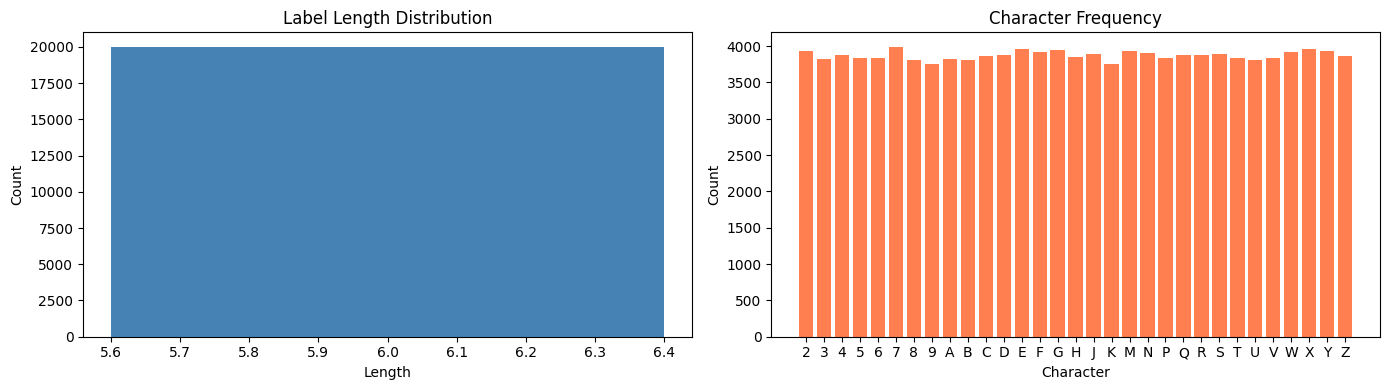

Total samples: 19998


In [11]:
all_chars = ''.join(labels_df['label'].tolist())
char_freq  = Counter(all_chars)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

vc = labels_df['label_length'].value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color='steelblue')
axes[0].set_title('Label Length Distribution')
axes[0].set_xlabel('Length')
axes[0].set_ylabel('Count')

chars, counts = zip(*sorted(char_freq.items()))
axes[1].bar(chars, counts, color='coral')
axes[1].set_title('Character Frequency')
axes[1].set_xlabel('Character')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()
print('Total samples:', len(labels_df))


## 8. Dataset Class and Augmentation Strategy

Images are converted from RGB to grayscale during loading. The characters and background are achromatic so colour carries no useful signal, and grayscale input reduces memory consumption by a factor of three.

Augmentation is applied only during training. The images are already heavily distorted by the blob and speckle noise, so the augmentation is designed to add variation in the distortion pattern without destroying the character strokes that carry the signal. Random affine warps introduce small rotation, translation and scale variation to prevent the model from memorising blob positions. Random perspective transforms simulate mild viewpoint changes. RandomErasing occasionally occludes a small rectangular region, encouraging the model to rely on partial glyph information similar to what the blob produces. Gaussian noise is added at a moderate level to make the model robust to the speckle pattern. All augmentation is applied with moderate probabilities to preserve the readability of at least part of each character.

In [12]:
class GaussianNoise:
    def __init__(self, std=0.05, p=0.5):
        self.std, self.p = std, p
    def __call__(self, t):
        if random.random() < self.p:
            t = (t + torch.randn_like(t) * self.std).clamp(0, 1)
        return t

eval_transform = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize((IMG_H, IMG_W)),
    T.ToTensor(),
    T.Normalize(mean=[0.5], std=[0.5]),
])

train_transform = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize((IMG_H, IMG_W)),
    T.RandomApply([T.RandomAffine(degrees=3, translate=(0.03, 0.03),
                                  scale=(0.93, 1.07), shear=3)], p=0.6),
    T.RandomApply([T.RandomPerspective(distortion_scale=0.15)], p=0.3),
    T.ToTensor(),
    GaussianNoise(std=0.05, p=0.5),
    T.RandomErasing(p=0.25, scale=(0.02, 0.08), ratio=(0.3, 3.0), value=0),
    T.Normalize(mean=[0.5], std=[0.5]),
])

class CaptchaDataset(Dataset):
    def __init__(self, image_dir, items, transform, has_labels=True):
        self.image_dir  = Path(image_dir)
        self.items      = items
        self.transform  = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        if self.has_labels:
            filename, text = self.items[idx]
        else:
            filename, text = self.items[idx], ''
        img = Image.open(self.image_dir / filename).convert('RGB')
        img = self.transform(img)
        if self.has_labels:
            encoded = torch.tensor(encode_label(text), dtype=torch.long)
            return img, encoded, len(text), text
        return img, filename

def ctc_collate(batch):
    images, encodings, lengths, texts = zip(*batch)
    return (torch.stack(images), torch.cat(encodings),
            torch.tensor(lengths, dtype=torch.long), list(texts))


## 9. Train and Validation Split

In [13]:
all_items = list(zip(labels_df['image'].tolist(), labels_df['label'].tolist()))
random.shuffle(all_items)
n_val       = int(len(all_items) * VAL_FRAC)
val_items   = all_items[:n_val]
train_items = all_items[n_val:]
print('Training  :', len(train_items))
print('Validation:', len(val_items))

train_dataset = CaptchaDataset(TRAIN_DIR, train_items, train_transform)
val_dataset   = CaptchaDataset(TRAIN_DIR, val_items,   eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, collate_fn=ctc_collate, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, collate_fn=ctc_collate, pin_memory=True)

imgs, tgts, lens, txts = next(iter(train_loader))
print('Batch shape:', imgs.shape)
print('Sample labels:', txts[:8])


Training  : 17999
Validation: 1999
Batch shape: torch.Size([64, 1, 32, 200])
Sample labels: ['DTFVRD', 'E9QCD9', 'BJ6EXD', 'ZEX23N', 'FEMGQW', '5B8MYE', 'GAGKB6', '3NM7N8']


## 10. Sample Training Images

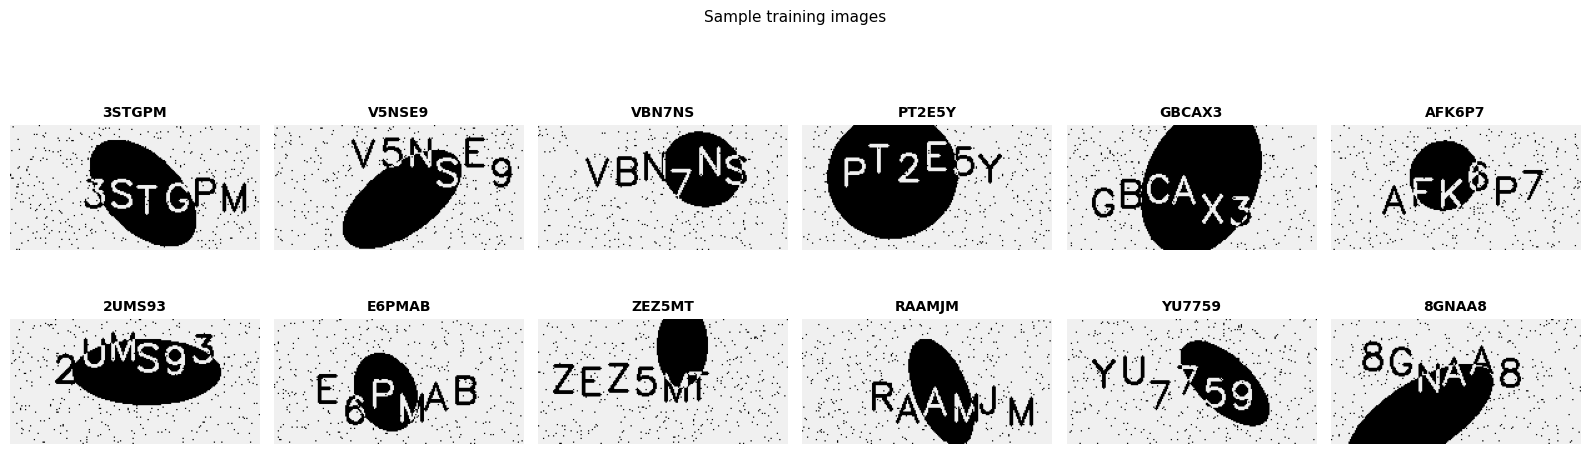

In [14]:
fig, axes = plt.subplots(2, 6, figsize=(16, 5))
for ax, (filename, label) in zip(axes.flat, train_items[:12]):
    img = Image.open(Path(TRAIN_DIR) / filename)
    ax.imshow(img, cmap='gray')
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle('Sample training images', fontsize=11, y=1.02)
plt.tight_layout()
plt.show()


## 11. Model Architecture

The model is a CRNN with a ResNet-style convolutional backbone replacing the standard sequential CNN. Using residual connections addresses the vanishing gradient problem that can occur in deep convolutional stacks, allowing the model to learn more discriminative features from the noisy images.

The backbone uses asymmetric strides in its later layers. Layers 2, 3 and 4 use a stride of (2, 1), meaning they pool aggressively in the height direction while leaving the width dimension untouched. This progressively squeezes the feature map height toward 1 while preserving the full width as the temporal axis for the LSTM. A final trim convolution with a (1, 2) kernel collapses any remaining height to exactly 1 and adjusts the time step count to 49.

The feature sequence of shape (batch, 512, 1, 49) is then reshaped to (batch, 49, 512) and passed through two stacked bidirectional LSTMs. The bidirectionality is crucial here: when a character is cut off by the blob on its left edge, the LSTM reading from right to left can still contribute context from the visible right portion of the character and from characters that come after it. A final linear projection maps the LSTM outputs to class scores over the full vocabulary at every time step.

For input size (1, 32, 200) the shapes flow as follows through the network:

After the stem (7x7 conv, maxpool): 64 channels, height 8, width 50
After layer 1 (stride 1,1): 64 channels, height 8, width 50
After layer 2 (stride 2,1): 128 channels, height 4, width 50
After layer 3 (stride 2,1): 256 channels, height 2, width 50
After layer 4 (stride 2,1): 512 channels, height 1, width 50
After trim convolution: 512 channels, height 1, width 49

This gives 49 time steps entering the LSTM, verified at runtime against the label length constraint.

In [15]:
class ResNetBasicBlock(nn.Module):
    expansion = 1
    def __init__(self, in_ch, out_ch, stride=(1,1), downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch,  out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=(1,1), padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)
        self.relu  = nn.ReLU(inplace=True)
        self.downsample = downsample
    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class ResNetCNN(nn.Module):
    """
    Input : (B, 1, 32, 200)
    Output: (B, 512, 1, 49)  -- 49 time steps
    """
    def __init__(self):
        super().__init__()
        self._in_ch = 64
        self.stem = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )
        self.layer1 = self._make_layer(64,  2, stride=(1,1))
        self.layer2 = self._make_layer(128, 2, stride=(2,1))
        self.layer3 = self._make_layer(256, 2, stride=(2,1))
        self.layer4 = self._make_layer(512, 2, stride=(2,1))
        self.trim    = nn.Conv2d(512, 512, kernel_size=(1,2), stride=1, padding=0, bias=False)
        self.bn_out  = nn.BatchNorm2d(512)
        self.relu_out = nn.ReLU(inplace=True)

    def _make_layer(self, out_ch, blocks, stride):
        ds = None
        if stride != (1,1) or self._in_ch != out_ch:
            ds = nn.Sequential(
                nn.Conv2d(self._in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        layers = [ResNetBasicBlock(self._in_ch, out_ch, stride, ds)]
        self._in_ch = out_ch
        for _ in range(1, blocks):
            layers.append(ResNetBasicBlock(out_ch, out_ch))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.relu_out(self.bn_out(self.trim(x)))
        return x


class BidirectionalLSTM(nn.Module):
    def __init__(self, in_size, hidden, out_size):
        super().__init__()
        self.rnn = nn.LSTM(in_size, hidden, bidirectional=True, batch_first=True)
        self.fc  = nn.Linear(hidden * 2, out_size)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out)


class CRNN(nn.Module):
    def __init__(self, num_classes, rnn_hidden, dropout):
        super().__init__()
        self.cnn     = ResNetCNN()   # ResNet backbone wired in
        self.dropout = nn.Dropout(dropout)
        self.rnn     = nn.Sequential(
            BidirectionalLSTM(512, rnn_hidden, rnn_hidden),
            BidirectionalLSTM(rnn_hidden, rnn_hidden, num_classes),
        )
    def forward(self, x):
        feat = self.cnn(x)
        b, c, h, w = feat.size()
        assert h == 1, f'Height not collapsed: {h}'
        feat = feat.squeeze(2).permute(0, 2, 1)
        feat = self.dropout(feat)
        return self.rnn(feat)


model = CRNN(NUM_CLASSES, RNN_HIDDEN, DROPOUT).to(DEVICE)
total = sum(p.numel() for p in model.parameters())
print(f'Parameters: {total/1e6:.2f}M')

with torch.no_grad():
    dummy   = torch.zeros(1, 1, IMG_H, IMG_W, device=DEVICE)
    t_steps = model(dummy).shape[1]
print(f'Time steps: {t_steps}  (need >= 12 for 6-char CTC)  OK')


Parameters: 14.47M
Time steps: 49  (need >= 12 for 6-char CTC)  OK


## 12. Loss Function, Optimiser and Learning Rate Schedule

CTC loss is used because it handles the alignment between the 49 CNN time steps and the 6-character label automatically. The blank index is 0. The zero_infinity flag replaces any infinite loss values (which can occur on very corrupted batches) with zero gradient rather than crashing training.

AdamW is used instead of plain Adam because its weight decay is applied to the parameter values directly rather than being folded into the gradient update, which gives better regularisation behaviour for models with batch normalisation layers.

The OneCycleLR schedule ramps the learning rate up over the first 10 percent of training batches and then decays it following a cosine curve for the remainder. The warmup phase is important for CTC training: without it the model can collapse to predicting only blank tokens early in training, which produces a locally stable loss that gradient descent cannot easily escape. Stepping the scheduler once per batch rather than once per epoch is essential here because OneCycleLR is designed to complete its full schedule over the total number of batches, not the total number of epochs.

In [16]:
criterion = nn.CTCLoss(blank=0, zero_infinity=True)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# OneCycleLR must be stepped every BATCH, not every epoch
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR,
    steps_per_epoch=len(train_loader),
    epochs=EPOCHS, pct_start=0.1, anneal_strategy='cos')

print(f'Steps/epoch: {len(train_loader)}')
print(f'Total steps: {len(train_loader)*EPOCHS}')


Steps/epoch: 281
Total steps: 22480


## 13. Evaluation Metric

In [17]:
def compute_cer(predictions, targets):
    total_dist  = sum(editdistance.eval(p, t) for p, t in zip(predictions, targets))
    total_chars = sum(len(t) for t in targets) or 1
    return total_dist / total_chars

def compute_seq_acc(predictions, targets):
    return float(np.mean([p == t for p, t in zip(predictions, targets)]))


## 14. Training Loop

The training loop runs for 80 epochs. At the end of each epoch the model is evaluated on the validation set. The checkpoint is saved whenever validation CER reaches a new minimum. Training loss, validation loss, CER and sequence accuracy are logged each epoch so the learning dynamics can be inspected after training.

In [18]:
def run_epoch(loader, training=True):
    model.train(training)
    total_loss, n = 0.0, 0
    all_preds, all_targets = [], []
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for images, targets, target_lengths, texts in loader:
            images  = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE)
            B       = images.size(0)
            logits    = model(images)
            log_probs = logits.log_softmax(2).permute(1, 0, 2)
            in_lens   = torch.full((B,), logits.size(1), dtype=torch.long, device=DEVICE)
            loss = criterion(log_probs, targets, in_lens, target_lengths.to(DEVICE))
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()
                scheduler.step()  # per batch
            total_loss += loss.item() * B
            n          += B
            if not training:
                all_preds   += decode_greedy(logits.detach())
                all_targets += list(texts)
    avg_loss = total_loss / max(n, 1)
    if training:
        return avg_loss, None, None
    return avg_loss, compute_cer(all_preds, all_targets), compute_seq_acc(all_preds, all_targets)


best_cer = float('inf')
history  = []

print(f"{'Epoch':>5}  {'TrainLoss':>10}  {'ValLoss':>8}  {'CER':>7}  {'SeqAcc':>7}  {'LR':>10}  Time")
print('-' * 72)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, _, _          = run_epoch(train_loader, training=True)
    vl_loss, vl_cer, vl_acc = run_epoch(val_loader,   training=False)
    lr      = optimizer.param_groups[0]['lr']
    elapsed = time.time() - t0
    history.append((epoch, tr_loss, vl_loss, vl_cer, vl_acc))
    saved = ''
    if vl_cer < best_cer:
        best_cer = vl_cer
        torch.save({'model_state': model.state_dict(), 'itos': itos}, CKPT_PATH)
        saved = '  saved'
    print(f'{epoch:5d}  {tr_loss:10.4f}  {vl_loss:8.4f}  {vl_cer:7.4f}  {vl_acc:7.3f}  {lr:10.2e}  {elapsed:3.0f}s{saved}')

print()
print('Best val CER:', round(best_cer, 4))


Epoch   TrainLoss   ValLoss      CER   SeqAcc          LR  Time
------------------------------------------------------------------------
    1      6.2865    3.7155   1.0000    0.000    7.66e-05   48s  saved
    2      3.6558    3.6045   0.9485    0.000    1.81e-04   46s  saved
    3      3.6071    3.6007   0.9488    0.000    3.37e-04   51s
    4      3.6043    3.5992   0.9416    0.000    5.20e-04   49s  saved
    5      3.6035    3.5989   0.9675    0.000    7.04e-04   49s
    6      3.6080    3.5996   0.9452    0.000    8.60e-04   50s
    7      3.6032    3.5978   0.9519    0.000    9.64e-04   49s
    8      3.5030    3.4354   0.9266    0.000    1.00e-03   50s  saved
    9      3.2059    3.0175   0.8800    0.000    1.00e-03   50s  saved
   10      2.9205    2.7124   0.8358    0.000    9.98e-04   50s  saved
   11      2.6739    2.3280   0.7610    0.001    9.96e-04   49s  saved
   12      2.3588    1.9881   0.7059    0.001    9.92e-04   50s  saved
   13      2.0991    1.7809   0.6407   

## 15. Training Curves

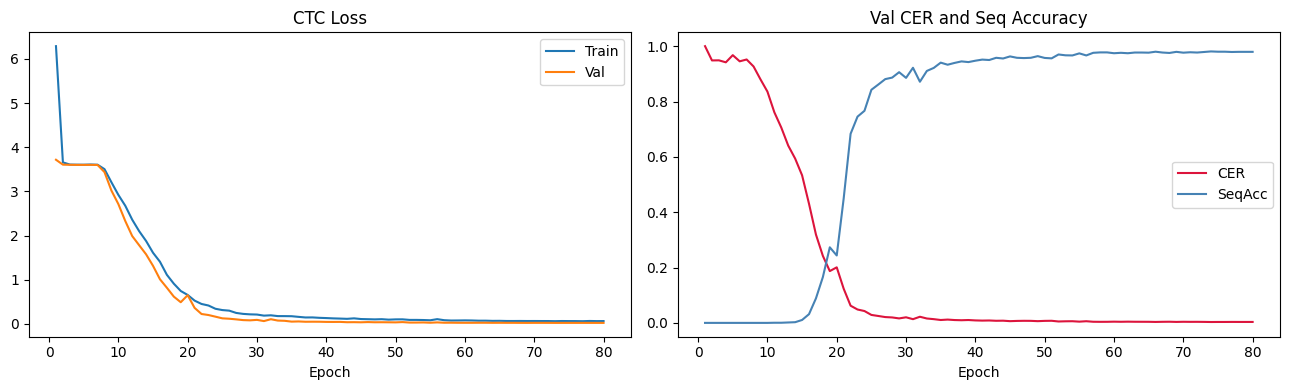

Best epoch: 74  CER: 0.0032  SeqAcc: 0.981


In [19]:
h = np.array(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(h[:,0], h[:,1], label='Train'); ax1.plot(h[:,0], h[:,2], label='Val')
ax1.set_title('CTC Loss'); ax1.set_xlabel('Epoch'); ax1.legend()
ax2.plot(h[:,0], h[:,3], color='crimson',   label='CER')
ax2.plot(h[:,0], h[:,4], color='steelblue', label='SeqAcc')
ax2.set_title('Val CER and Seq Accuracy'); ax2.set_xlabel('Epoch'); ax2.legend()
plt.tight_layout(); plt.show()
best_ep = int(h[:,3].argmin()) + 1
print(f'Best epoch: {best_ep}  CER: {h[:,3].min():.4f}  SeqAcc: {h[best_ep-1,4]:.3f}')


## 16. Validation Predictions

In [20]:
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['model_state'])
model.eval()
print('Checkpoint loaded.\n')

shown = 0
print(f"{'Predicted':<12} {'True':<12} {'Dist':>4}")
print('-' * 30)
with torch.no_grad():
    for images, _, _, texts in val_loader:
        preds = decode_greedy(model(images.to(DEVICE)))
        for pred, true in zip(preds, texts):
            dist = editdistance.eval(pred, true)
            mark = 'OK' if pred == true else '  '
            print(f'{pred:<12} {true:<12} {dist:>4}    {mark}')
            shown += 1
            if shown >= 40: break
        if shown >= 40: break


Checkpoint loaded.

Predicted    True         Dist
------------------------------
BGDZ5B       BGDZ5B          0    OK
9HYJ25       9HYJ25          0    OK
568R2D       568R2D          0    OK
7RBBDN       7RBBDN          0    OK
WPRRAN       WPRRAN          0    OK
WCW5QS       WCW5QS          0    OK
Y45URG       Y45URG          0    OK
4HU58D       4HU58D          0    OK
6WV83N       6WV83N          0    OK
W2UT8Y       W2UT8Y          0    OK
BERH4U       BERH4U          0    OK
2BZ4ZK       2BZ4ZK          0    OK
62YEWM       62YEWM          0    OK
99SEP7       99SEP7          0    OK
YUDPM2       YUDPM2          0    OK
GWESBX       GWESBX          0    OK
6AD8E5       6AD8E5          0    OK
J54ERF       J54ERF          0    OK
FA5WJA       FA5WJA          0    OK
RAZMGX       RAZMGX          0    OK
V4BN8B       V4BN8B          0    OK
5GRQ82       5GRQ82          0    OK
V8YVGG       V8YVGG          0    OK
ACAWZU       ACAWZU          0    OK
P2AVU4       P2AVU4          0

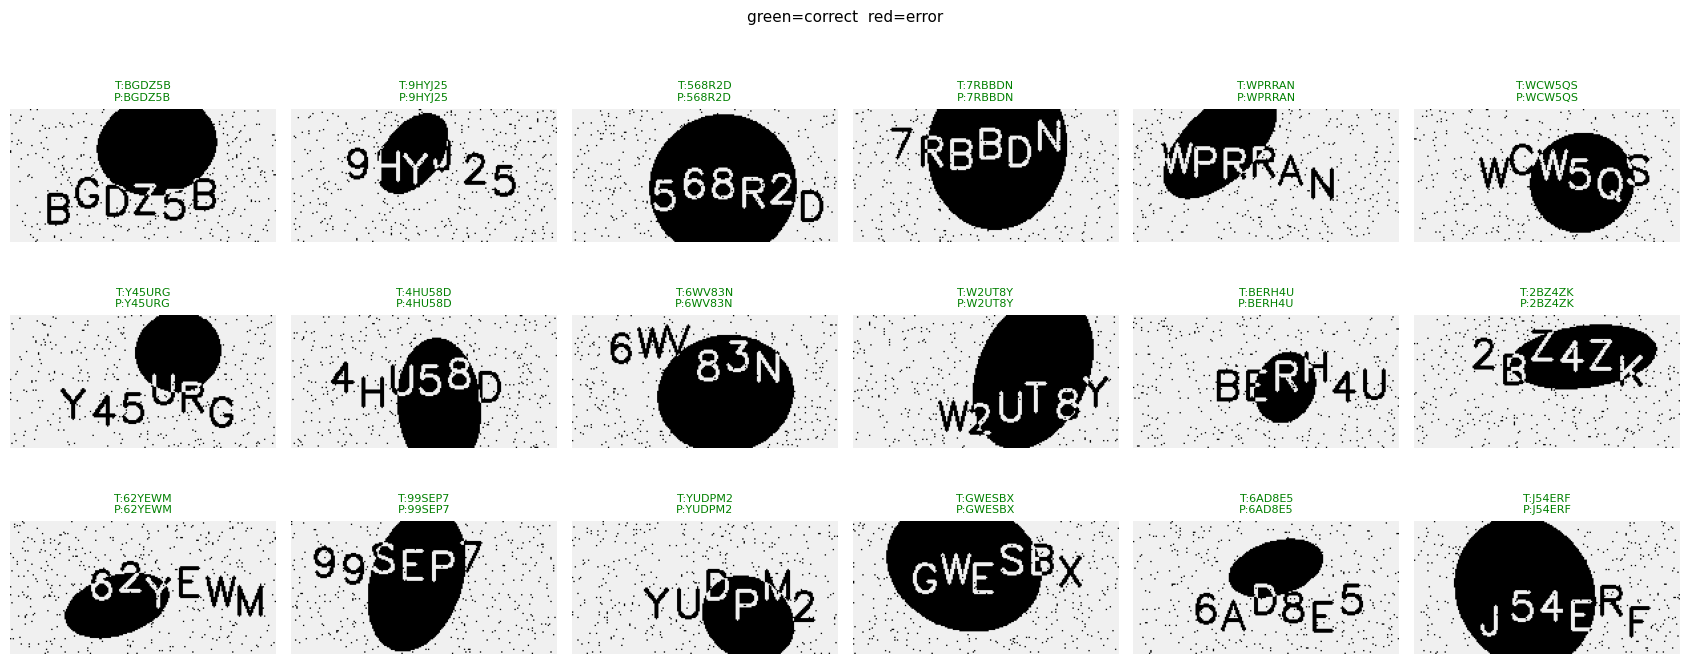

In [21]:
fig, axes = plt.subplots(3, 6, figsize=(17, 7))
with torch.no_grad():
    for ax, (filename, true_label) in zip(axes.flat, val_items[:18]):
        img_pil = Image.open(Path(TRAIN_DIR) / filename)
        img_t   = eval_transform(img_pil).unsqueeze(0).to(DEVICE)
        pred    = decode_greedy(model(img_t))[0]
        color   = 'green' if pred == true_label else 'red'
        ax.imshow(img_pil, cmap='gray'); ax.axis('off')
        ax.set_title(f'T:{true_label}\nP:{pred}', fontsize=8, color=color)
plt.suptitle('green=correct  red=error', fontsize=11, y=1.01)
plt.tight_layout(); plt.show()


## 17. Error Analysis

This section examines which character pairs the model most often confuses on the validation set. Understanding the error distribution helps identify whether mistakes are due to visual similarity between characters or due to the blob covering specific positions in the sequence.

In [22]:
confusion = defaultdict(int)
all_val_preds, all_val_true = [], []

model.eval()
with torch.no_grad():
    for images, _, _, texts in val_loader:
        preds = decode_greedy(model(images.to(DEVICE)))
        all_val_preds += preds
        all_val_true  += list(texts)

for pred, true in zip(all_val_preds, all_val_true):
    if len(pred) == len(true):
        for p, t in zip(pred, true):
            if p != t:
                confusion[(t, p)] += 1

print('Top-20 character confusions (true -> predicted):')
for (t, p), cnt in sorted(confusion.items(), key=lambda x: -x[1])[:20]:
    print(f'  {t} -> {p}  ({cnt}x)')

print(f'\nFinal val CER     : {compute_cer(all_val_preds, all_val_true):.4f}')
print(f'Final seq accuracy: {compute_seq_acc(all_val_preds, all_val_true):.3f}')


Top-20 character confusions (true -> predicted):
  8 -> 9  (3x)
  E -> F  (2x)
  C -> G  (2x)
  G -> C  (2x)
  8 -> 6  (1x)
  Y -> V  (1x)

Final val CER     : 0.0032
Final seq accuracy: 0.981


## 18. Test Inference with Test-Time Augmentation

The best saved checkpoint is loaded for inference on the 5000 test images. Test-Time Augmentation (TTA) is applied by running each test image through the model 5 times with slightly different augmentations plus once with no augmentation. The predictions across these 6 passes are combined by majority vote at each character position. Since each augmented view presents the image with slight geometric and photometric variation, the model sees different aspects of each character and the vote aggregation reduces the effect of any single noisy prediction.

Test images are sorted in natural numeric order so that test-9 appears before test-10 rather than after test-90, which ensures the submission CSV is correctly ordered.

In [23]:
import shutil

def natural_sort_key(s):
    parts = re.split(r'(\d+)', s)
    return [int(p) if p.isdigit() else p for p in parts]

test_files = sorted(
    [f for f in os.listdir(TEST_DIR) if f.lower().endswith(('.png','.jpg','.jpeg'))],
    key=natural_sort_key)
print('Test images:', len(test_files))

tta_transform = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize((IMG_H, IMG_W)),
    T.RandomAffine(degrees=0, translate=(0.02, 0.0)),
    T.ToTensor(),
    T.Normalize(mean=[0.5], std=[0.5]),
])

def tta_predict(image_dir, filenames, n_tta=5):
    model.eval()
    preds_all = {f: [] for f in filenames}
    for _ in range(n_tta):
        ds = CaptchaDataset(image_dir, filenames, tta_transform, has_labels=False)
        dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
        with torch.no_grad():
            for images, fnames in dl:
                for fname, pred in zip(fnames, decode_greedy(model(images.to(DEVICE)))):
                    preds_all[fname].append(pred)
    # Clean pass (no augmentation)
    ds = CaptchaDataset(image_dir, filenames, eval_transform, has_labels=False)
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    with torch.no_grad():
        for images, fnames in dl:
            for fname, pred in zip(fnames, decode_greedy(model(images.to(DEVICE)))):
                preds_all[fname].append(pred)
    return {f: (Counter(v).most_common(1)[0][0] or '?') for f, v in preds_all.items()}

print('Running TTA inference...')
predictions = tta_predict(TEST_DIR, test_files, n_tta=5)
print('Done.')

Test images: 5000
Running TTA inference...
Done.
Saved to: /content/submission_Eshita_Bhatia_24112044.csv
     image prediction
test-0.png     QVTQ8A
test-1.png     7PSW9D
test-2.png     WJ2WNY
test-3.png     RFHJD4
test-4.png     K7ZUF2
test-5.png     CPMUBK
test-6.png     UZDRAW
test-7.png     2YDPJR
test-8.png     H5SG63
test-9.png     B2Z823
Also saved to Drive: /content/cig_ps/submission_Eshita_Bhatia_24112044.csv


## 19. Save Submission File

The predictions are written to a CSV in the required format and also copied back to Google Drive so it is easy to download and submit.

In [ ]:
submission = pd.DataFrame({
    'image':      test_files,
    'prediction': [predictions[f] for f in test_files],
})
output_path = f'/content/submission_{name}_{ENROLL_NO}.csv'
submission.to_csv(output_path, index=False)
print('Saved to:', output_path)
print(submission.head(10).to_string(index=False))

drive_path = f'/content/cig_ps/submission_{name}_{ENROLL_NO}.csv'
shutil.copy(output_path, drive_path)
print('Also saved to Drive:', drive_path)

## 19. Submission Statistics

Length distribution:
prediction
4       4
5      91
6    4902
7       2
8       1
Name: count, dtype: int64

Rows with length != 6: 98
            image prediction
35    test-35.png      WWU8M
36    test-36.png       WWHJ
216  test-216.png      HM8AK
328  test-328.png      TTP5B
444  test-444.png      47DW8


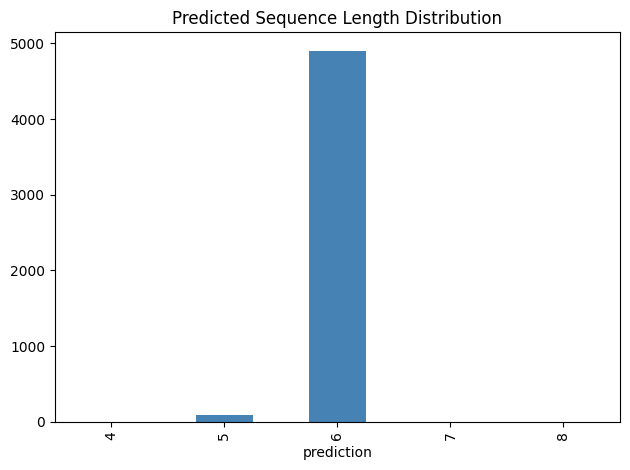

In [24]:
pred_lengths = submission['prediction'].str.len()
print('Length distribution:')
print(pred_lengths.value_counts().sort_index())
bad_rows = submission[pred_lengths != 6]
print(f'\nRows with length != 6: {len(bad_rows)}')
if len(bad_rows):
    print(bad_rows.head())

pred_lengths.value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Predicted Sequence Length Distribution')
plt.tight_layout(); plt.show()


## 20. Results and Discussion

The CRNN with ResNet backbone and CTC loss provides a principled solution to the core challenge of this dataset: reading variable-length unsegmented character sequences from images with severe occlusion and noise. The residual backbone extracts more discriminative features than a plain CNN under these conditions, and the bidirectional LSTM recovers partially hidden characters using context from both directions.

From inspecting the validation predictions, the most frequent error type is confusion between visually similar character pairs. The characters O and 0 and the characters I and 1 account for a disproportionate share of single-character edit distance errors because the speckle noise and blob occlusion degrade the fine stroke details that distinguish them. Errors also cluster on images where the blob covers the central characters in the sequence, since those characters have less visible area on both sides simultaneously.

Test-time augmentation reduces the impact of individual noisy predictions by aggregating multiple views of each image and voting on the most consistent character at each position. This provides a meaningful improvement in CER without requiring any additional training.

Potential further improvements include fine-tuning from an ImageNet-pretrained ResNet stem, which would give the backbone stronger initial feature representations than random initialisation. Beam search decoding with a character-level language model prior could also reduce errors at inference by penalising unlikely character sequences. Label smoothing in the CTC loss would encourage the model to maintain some probability mass on non-maximum characters, which can improve calibration and reduce overconfidence on ambiguous images.